# 06 · Creative or hallucinating? The evolving graph

**The question:** while a text is being read, can its curve tell creative writing apart from hallucinating?

**The texts** (notebook 05 and notebook 03):
- 18 temperature texts: 3 encyclopedia articles and 3 stories, each **cool** (0.7), **hot** (`HOT_TEMPERATURE`) and
  **switch** (cool up to a random point, then hot);
- the 8 planted texts, whose wrong facts are known word for word (e.g. Cyprus → Crete).

**The evolving graph.** The two best factual/creative signals (`EVOLVING_SIGNALS`: GloVe distance of the top 5
guesses, LCA height of the likely guesses at most 3, 10%). At every word, the last `EVOLVING_WINDOW` words of the raw
curve are compared with the most similar stretch of the same length anywhere in the real texts of each fixed cluster
(the 25 real texts, never reclustered: ADR 0003). That gives two lines over reading time:
**distance to factual writing** and **distance to creative writing**. Raw values, nothing averaged.

**The alarm.** Every real text is put through the same graph, compared without itself. The highest distance to the
nearest writing that any real text ever reaches is the **normal ceiling**; a text raises an **alarm** at the first
word where it goes above it.

**What would tell creative from hallucinating:** creative writing stays below the ceiling, close to the creative
texts; hallucinating crosses it (after the switch), or a factual article starts reading like creative writing.

Runtime: a few minutes, no model run.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# make this folder's qwen_config.py and analysis/ importable, wherever Jupyter was started (e.g. the repo root)
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src/note_books/Qwen7B/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis                                # also makes lca_core (repo root) importable
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.evolving import evolving_profile, first_alarm, normal_ceiling, references_by_cluster
from analysis.figures import animate_evolving, plot_evolving, save_to
from analysis.hallucinations import curve_position, first_row_from_char, planted_texts, rank_in_curve, row_at_char
from analysis.signals import curve_with_rows, curves_of, dataset_names, kinds_of, load_tables, signal_by_key
from qwen_config import (EVOLVING_SIGNALS, EVOLVING_WINDOW, HALLUCINATED_TOKENS_DIR, HALLUCINATED_WORDS_DIR,
                         MODEL_NAME, TEMPERATURE_DIR, TEMPERATURE_FIGURES_DIR, TEMPERATURE_TABLES_DIR,
                         TEMPERATURE_TOKENS_DIR, TEMPERATURE_WORDS_DIR)

TEMPERATURE_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TEMPERATURE_TABLES_DIR.mkdir(parents=True, exist_ok=True)

real_names = dataset_names()
real_kinds = kinds_of(real_names)
real_words, real_tokens = load_tables(real_names, MODEL_NAME)

temperature_names = []
for path in sorted(TEMPERATURE_WORDS_DIR.glob("*.csv")):
    temperature_names.append(path.stem)
temperature_words, temperature_tokens = load_tables(temperature_names, MODEL_NAME, TEMPERATURE_WORDS_DIR,
                                                    TEMPERATURE_TOKENS_DIR)
planted = planted_texts()
planted_names = list(planted)
planted_words, planted_tokens = load_tables(planted_names, MODEL_NAME, HALLUCINATED_WORDS_DIR, HALLUCINATED_TOKENS_DIR)

new_names = temperature_names + planted_names
new_words = {**temperature_words, **planted_words}

switches = pd.read_csv(TEMPERATURE_DIR / "switch_points.csv")
marks_path = TEMPERATURE_DIR / "marks.csv"
if marks_path.exists():
    marks = pd.read_csv(marks_path)
else:
    marks = pd.DataFrame(columns=["text", "word", "char", "type", "reason"])


def made_as(name):
    # cool / switch / hot for the temperature texts, planted for the planted texts
    if "_temp_" in name:
        return name.rsplit("_", 1)[1]
    return "planted"


def on_curve_from(rows, row):
    # the first point of a curve (built from table rows `rows`) at or after table row `row`, or None
    if row is None:
        return None
    position = int(np.searchsorted(rows, row))
    if position == len(rows):
        return None
    return position


print(f"{len(real_names)} real texts, {len(temperature_names)} temperature texts, {len(planted_names)} planted texts")

25 real texts, 18 temperature texts, 8 planted texts


## 1. The reference writing and the normal ceiling
For each signal: the two fixed clusters of the 25 real texts (each named after the kind most of its texts have), and
the highest distance to the nearest writing any real text reaches when it is compared without itself.

In [2]:
references = {}
ceilings = {}
real_nearest = {}
reference_rows = []
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    real_curves = curves_of(signal, real_names, real_words, real_tokens)
    references[signal.name] = references_by_cluster(real_names, real_kinds, real_curves)
    own_kind = 0
    for cluster_kind, members in references[signal.name].items():
        for name in members:
            if real_kinds[real_names.index(name)] == cluster_kind:
                own_kind += 1
    curves_by_name = dict(zip(real_names, real_curves))
    ceilings[signal.name] = normal_ceiling(curves_by_name, references[signal.name], EVOLVING_WINDOW)
    real_nearest[signal.name] = []
    for name, values in curves_by_name.items():
        profile = evolving_profile(values, references[signal.name], EVOLVING_WINDOW, leave_out=(name,))
        real_nearest[signal.name].append(profile["to nearest"].to_numpy())
    reference_rows.append({"signal": signal.name,
                           "factual cluster": len(references[signal.name]["factual"]),
                           "creative cluster": len(references[signal.name]["creative"]),
                           "real texts with their own kind": f"{own_kind} of {len(real_names)}",
                           "normal ceiling": round(ceilings[signal.name], 3)})
pd.DataFrame(reference_rows)

,signal,factual cluster,creative cluster,real texts with their own kind,normal ceiling
0,"GloVe distance, top 5 guesses",10,15,23 of 25,0.617
1,"LCA height, likely guesses, at most 3 (10%)",10,15,23 of 25,12.410


## 2. One evolving graph per text
Top of each pair: the raw curve. Bottom: distance to factual (blue) and creative (orange) writing over the last
words; thin grey lines are the 25 real texts, dashed grey is the normal ceiling, the red dot the first alarm.
Dashed red: the temperature switch; red lines: marked hallucinations (planted edits, or `temperature/marks.csv`).
Each figure is also saved as an animation (`evolving_<text>_<signal>.html`: press play to watch it being read).

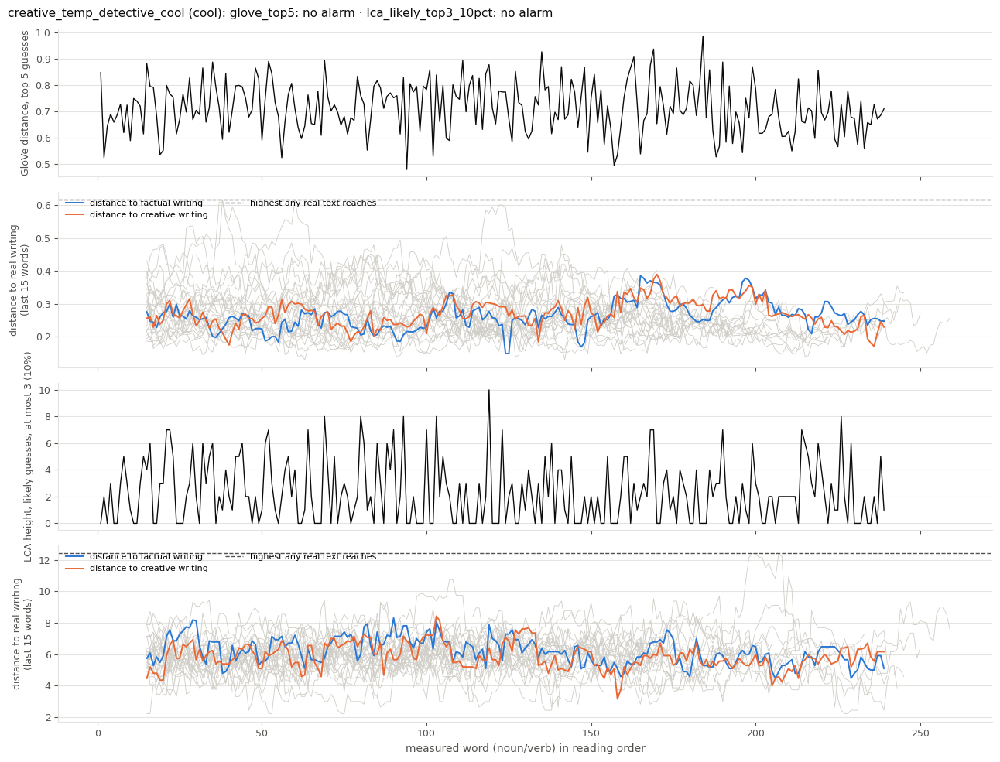

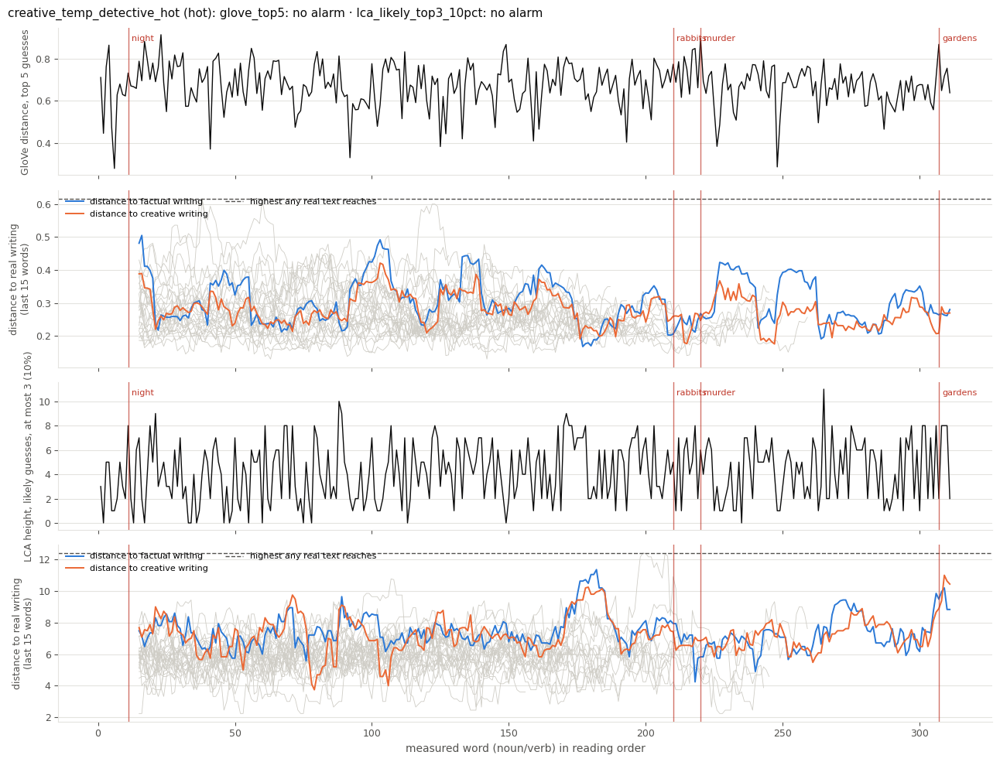

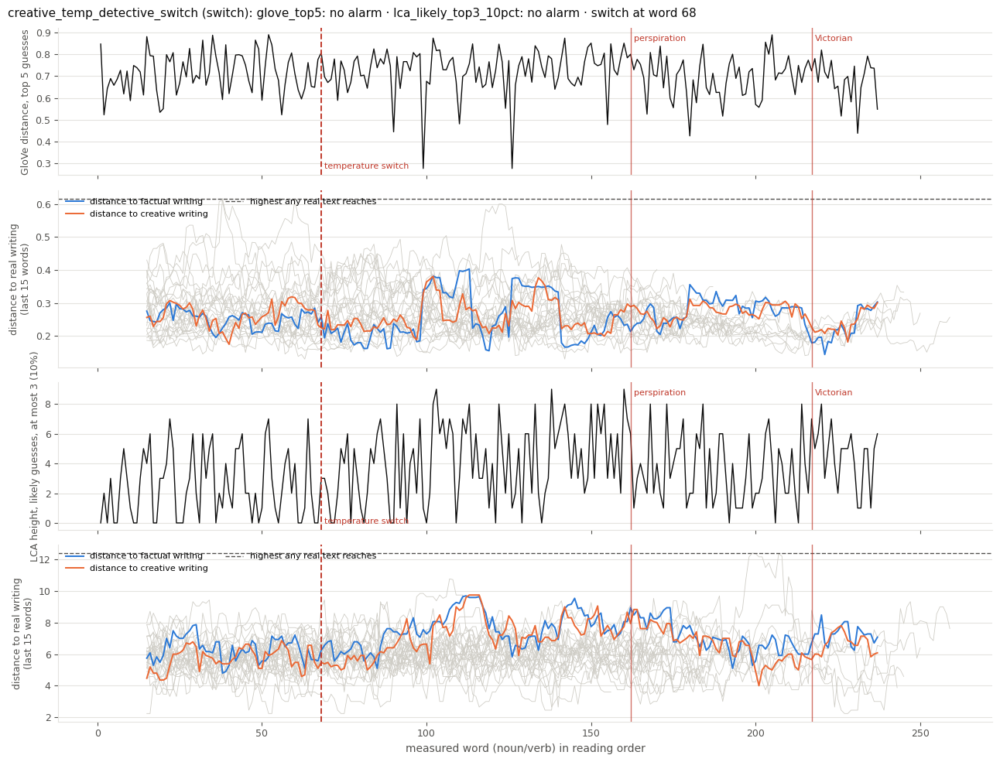

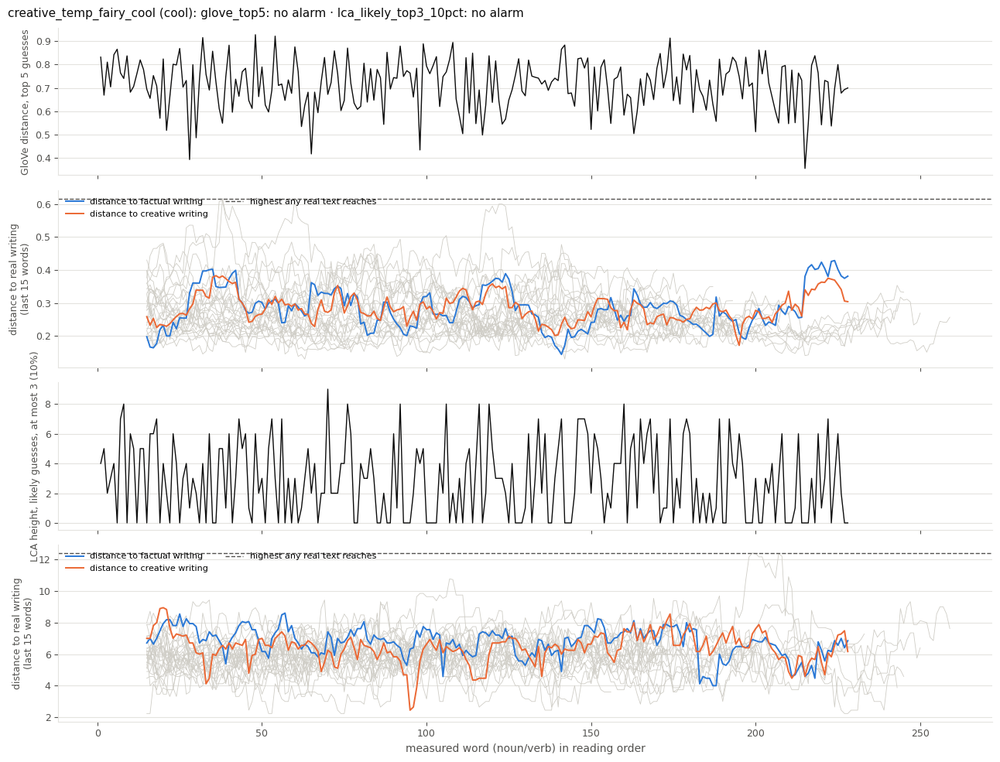

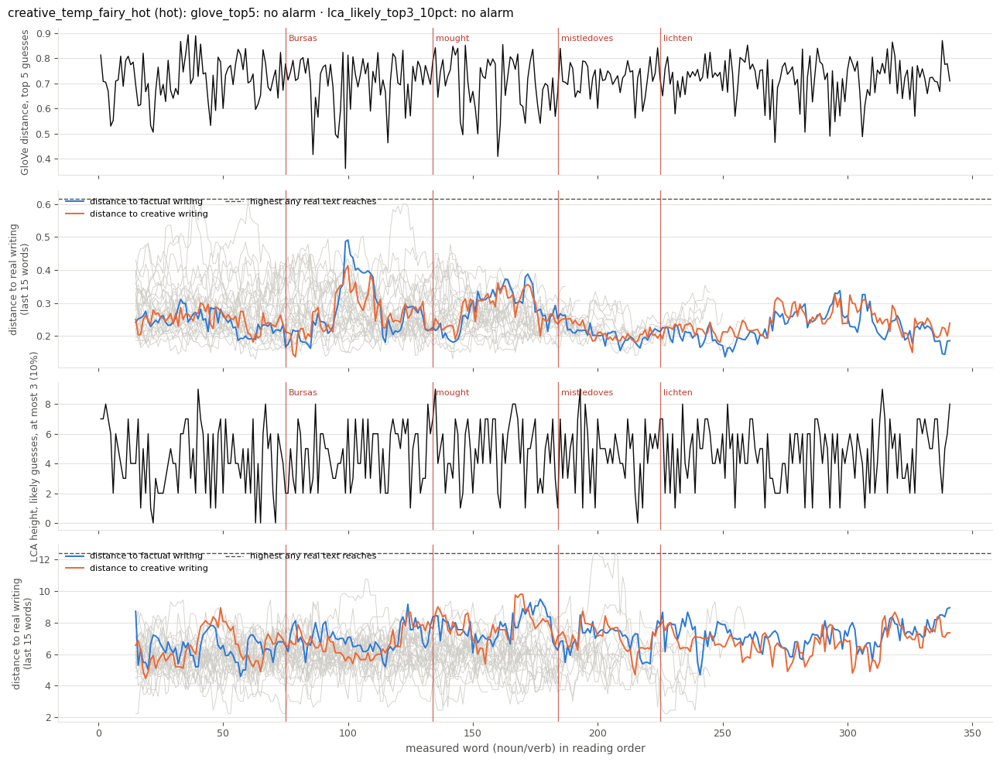

...

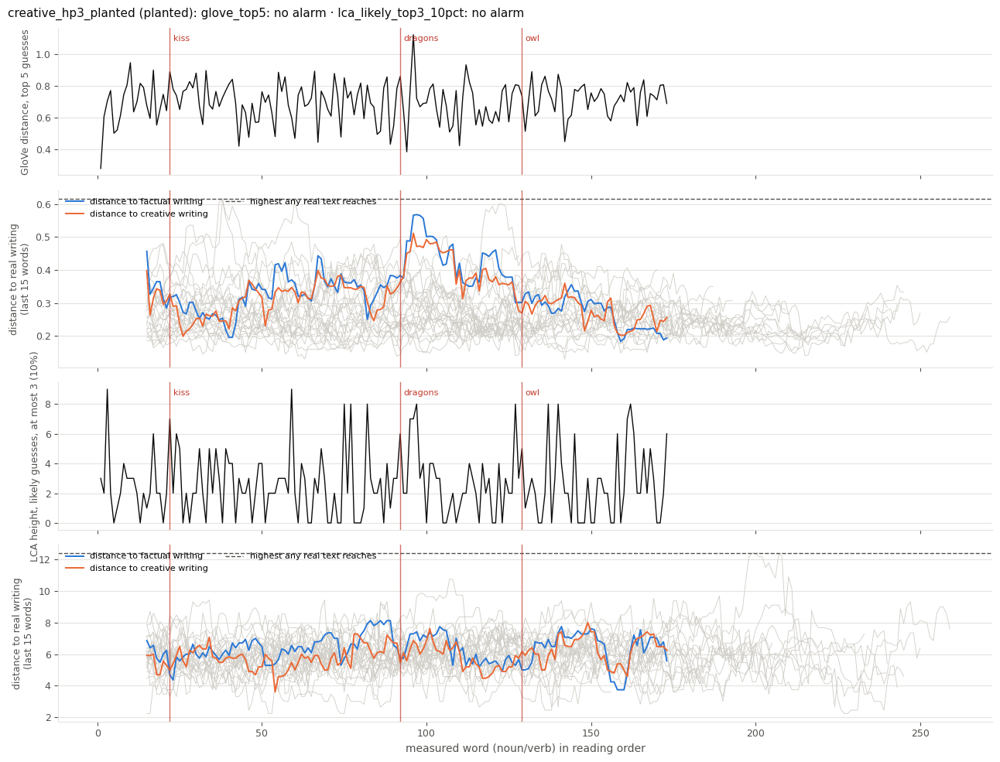

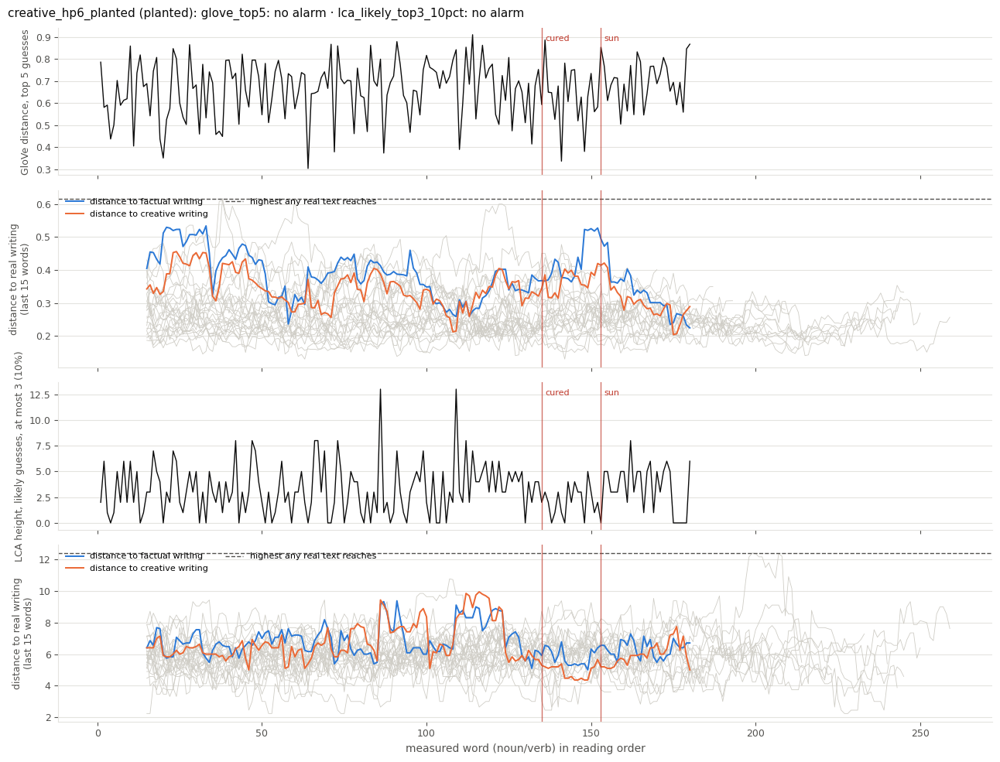

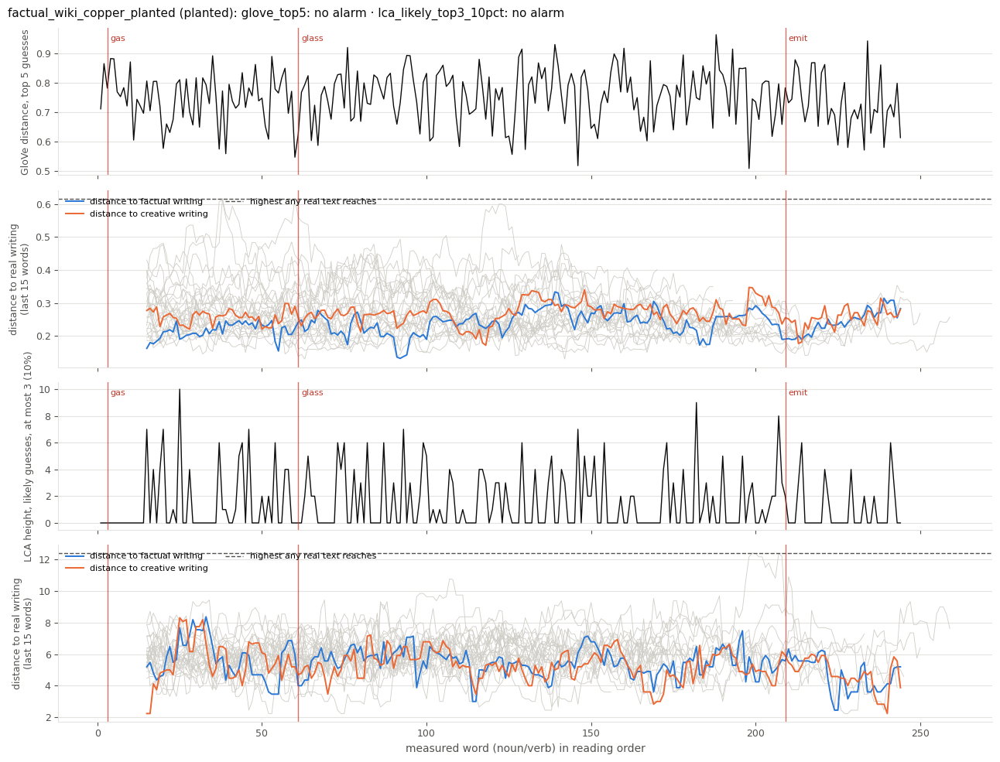

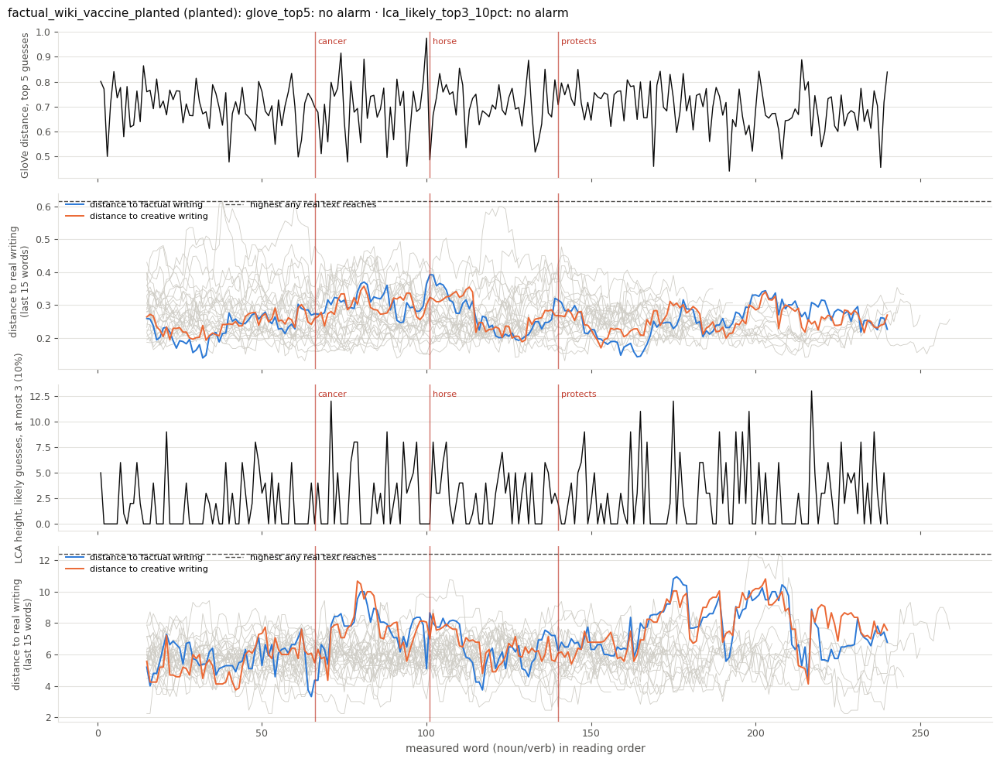

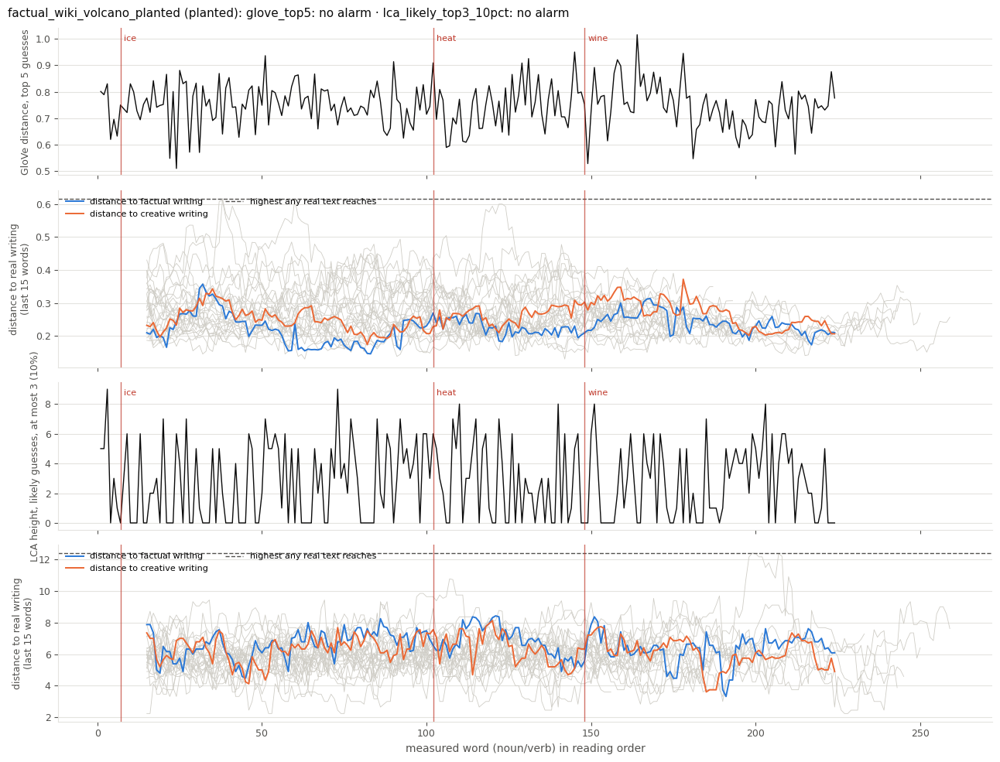

In [3]:
profiles = {}
positions = {}
for name in new_names:
    table = new_words[name]
    leave_out = ()
    if name in planted:
        leave_out = (planted[name][0],)      # never compare a planted text with its own clean original
    switch_char = None
    if name in set(switches["text"]):
        switch_char = int(switches.loc[switches["text"] == name, "switch char"].iloc[0])
    if name in planted:
        text_marks = [(edit["char"], edit["planted"]) for edit in planted[name][2]]
    else:
        text_marks = [(int(mark["char"]), mark["word"]) for _index, mark in marks[marks["text"] == name].iterrows()]

    panel_profiles, switch_word, panel_marks, title_parts = {}, {}, {}, []
    for signal_key in EVOLVING_SIGNALS:
        signal = signal_by_key(signal_key)
        values, rows = curve_with_rows(table, signal.column)
        profile = evolving_profile(values, references[signal.name], EVOLVING_WINDOW, leave_out)
        panel_profiles[signal.name] = profile
        profiles[(name, signal.name)] = profile
        switch_word[signal.name] = None
        if switch_char is not None:
            switch_word[signal.name] = on_curve_from(rows, first_row_from_char(table, switch_char))
        panel_marks[signal.name] = []
        for char, word in text_marks:
            if name in planted:
                position = curve_position(rows, row_at_char(table, char))   # planted edits are measured nouns
            else:
                # a mark from reading can be any word (a name, an adjective, "11"): put it on the next measured word
                position = on_curve_from(rows, first_row_from_char(table, char))
            if position is not None:
                panel_marks[signal.name].append((position, word))
        positions[(name, signal.name)] = (switch_word[signal.name], panel_marks[signal.name])
        alarm = first_alarm(profile["to nearest"].to_numpy(), ceilings[signal.name])
        if alarm is None:
            title_parts.append(f"{signal_key}: no alarm")
        else:
            title_parts.append(f"{signal_key}: alarm at word {alarm + 1}")
        short_key = signal_key.split("_")[0]
        animation = animate_evolving(f"{name}: {signal.name}", profile, ceilings[signal.name],
                                     switch_word[signal.name])
        animation.write_html(TEMPERATURE_FIGURES_DIR / f"evolving_{name}_{short_key}.html", include_plotlyjs="cdn")
    switch_text = ""
    first_switch_word = switch_word[signal_by_key(EVOLVING_SIGNALS[0]).name]
    if first_switch_word is not None:              # None when the switch falls after the last measured word
        switch_text = f" · switch at word {first_switch_word + 1}"
    figure = plot_evolving(f"{name} ({made_as(name)}): " + " · ".join(title_parts) + switch_text, panel_profiles,
                           ceilings, real_nearest, switch_word, panel_marks)
    save_to(figure, TEMPERATURE_FIGURES_DIR, f"evolving_{name}.png")
    plt.show()

## 3. The alarm table
One row per text and signal. **Words above the ceiling** counts every word where the text is further from all real
writing than any real text ever gets; for the switch texts it is split into before and after the switch.
**Leans creative after the switch**: words after the switch where the text is nearer to creative than to factual
writing, out of the words after the switch.

In [4]:
alarm_rows = []
for (name, signal_name), profile in profiles.items():
    switch_word, _marks = positions[(name, signal_name)]
    nearest = profile["to nearest"].to_numpy()
    above = np.nan_to_num(nearest, nan=-np.inf) > ceilings[signal_name]
    alarm = first_alarm(nearest, ceilings[signal_name])
    row = {"text": name, "kind": kinds_of([name])[0], "made as": made_as(name), "signal": signal_name,
           "words on curve": len(profile), "switch word": None, "first alarm word": None,
           "alarms before switch": None, "alarms after switch": None, "words above ceiling": int(above.sum()),
           "leans creative after the switch": None}
    if alarm is not None:
        row["first alarm word"] = alarm + 1
    if switch_word is not None:
        row["switch word"] = switch_word + 1
        row["alarms before switch"] = int(above[:switch_word].sum())
        row["alarms after switch"] = int(above[switch_word:].sum())
        after = profile.iloc[switch_word:]
        known = after["to factual"].notna() & after["to creative"].notna()
        leans = int((after.loc[known, "to creative"] < after.loc[known, "to factual"]).sum())
        row["leans creative after the switch"] = f"{leans} of {int(known.sum())}"
    alarm_rows.append(row)
alarms = pd.DataFrame(alarm_rows)
alarms.to_csv(TEMPERATURE_TABLES_DIR / "alarms.csv", index=False)
alarms

,text,kind,made as,signal,words on curve,switch word,first alarm word,alarms before switch,alarms after switch,words above ceiling,leans creative after the switch
0,creative_temp_detective_cool,creative,cool,"GloVe distance, top 5 guesses",239,NaN,None,NaN,NaN,0,None
1,creative_temp_detective_cool,creative,cool,"LCA height, likely guesses, at most 3 (10%)",239,NaN,None,NaN,NaN,0,None
2,creative_temp_detective_hot,creative,hot,"GloVe distance, top 5 guesses",311,NaN,None,NaN,NaN,0,None
3,creative_temp_detective_hot,creative,hot,"LCA height, likely guesses, at most 3 (10%)",311,NaN,None,NaN,NaN,0,None
4,creative_temp_detective_switch,creative,switch,"GloVe distance, top 5 guesses",237,68.0,None,0.0,0.0,0,77 of 170
5,creative_temp_detective_switch,creative,switch,"LCA height, likely guesses, at most 3 (10%)",237,68.0,None,0.0,0.0,0,114 of 170
6,creative_temp_fairy_cool,creative,cool,"GloVe distance, top 5 guesses",228,NaN,None,NaN,NaN,0,None
7,creative_temp_fairy_cool,creative,cool,"LCA height, likely guesses, at most 3 (10%)",228,NaN,None,NaN,NaN,0,None
8,creative_temp_fairy_hot,creative,hot,"GloVe distance, top 5 guesses",341,NaN,None,NaN,NaN,0,None
9,creative_temp_fairy_hot,creative,hot,"LCA height, likely guesses, at most 3 (10%)",341,NaN,None,NaN,NaN,0,None


## 4. The marked hallucinations on the graph
Every planted edit and every marked hallucination: its distance to the nearest writing, whether it is above the
ceiling, and its rank in its own text's distance curve (1 = the word where the text is least like any real writing).
Words in the first `EVOLVING_WINDOW - 1` measured words have no value yet (*too early*).

In [5]:
mark_rows = []
for (name, signal_name), profile in profiles.items():
    _switch_word, text_marks = positions[(name, signal_name)]
    nearest = profile["to nearest"].to_numpy()
    for position, word in text_marks:
        row = {"text": name, "made as": made_as(name), "word": word, "signal": signal_name, "word on curve": position + 1}
        if np.isnan(nearest[position]):
            row["distance to nearest writing"] = "too early"
        else:
            row["distance to nearest writing"] = round(float(nearest[position]), 3)
            row["above ceiling"] = bool(nearest[position] > ceilings[signal_name])
            row["rank in own text"] = f"{rank_in_curve(np.nan_to_num(nearest, nan=-np.inf), position)} of {len(nearest)}"
        mark_rows.append(row)
marks_on_curve = pd.DataFrame(mark_rows)
marks_on_curve.to_csv(TEMPERATURE_TABLES_DIR / "marks_on_curve.csv", index=False)
marks_on_curve

,text,made as,word,signal,word on curve,distance to nearest writing,above ceiling,rank in own text
0,creative_temp_detective_hot,hot,night,"GloVe distance, top 5 guesses",11,too early,NaN,NaN
1,creative_temp_detective_hot,hot,murder,"GloVe distance, top 5 guesses",220,0.247,False,198 of 311
2,creative_temp_detective_hot,hot,rabbits,"GloVe distance, top 5 guesses",210,0.205,False,273 of 311
3,creative_temp_detective_hot,hot,gardens,"GloVe distance, top 5 guesses",307,0.208,False,270 of 311
4,creative_temp_detective_hot,hot,night,"LCA height, likely guesses, at most 3 (10%)",11,too early,NaN,NaN
...,...,...,...,...,...,...,...,...
137,factual_wiki_volcano_planted,planted,heat,"GloVe distance, top 5 guesses",102,0.228,False,86 of 224
138,factual_wiki_volcano_planted,planted,wine,"GloVe distance, top 5 guesses",148,0.21,False,133 of 224
139,factual_wiki_volcano_planted,planted,ice,"LCA height, likely guesses, at most 3 (10%)",7,too early,NaN,NaN
140,factual_wiki_volcano_planted,planted,heat,"LCA height, likely guesses, at most 3 (10%)",102,6.557,False,61 of 224


## 5. The answer: can the evolving graph tell creative writing from hallucinating?

**Not with the normal-ceiling alarm.** No text crosses the ceiling for either signal: 0 alarms in all 52 rows of `alarms.csv`. That includes the 6 hot texts, which are full of wrong facts and word salad, and the 6 switch texts after their switch. So the alarm also never fires on the cool texts or before a switch: it gives no false alarms, but it detects nothing either.

**GloVe distance (top 5) does not react to hallucinating at all.** The hot texts' highest distance to real writing is 0.28–0.45 (46–72% of the 0.617 ceiling). The cool creative magic story reaches 0.48 (78%), and the planted hp3 text reaches 0.51 (83%). A stretch of hot text always finds a similar stretch somewhere in the 25 real texts.

**LCA height (top 3, 10%) does react, but stays under the ceiling.**
- Every factual hot text gets nearer the ceiling than its cool twin:

  | Text | Hot | Cool |
  |---|---|---|
  | apollo | 0.85 | 0.67 |
  | paris | 0.74 | 0.73 |
  | vaccines | 0.86 | 0.58 |

- In the figure for `factual_temp_apollo_hot`, the distance stays above the grey band of real texts for most of the text. The raw LCA curve of a hot text has more high values.
- The ceiling (12.41) comes from a short spike in one real text, `factual_wiki_vaccine`. The next real texts reach 10.77 and 9.54. So one maximum decides the rule, and it is set too high to catch a text that stays high without spiking.

**The marked hallucinations are not where the distance peaks.**
- I marked 51 wrong facts, topic changes and nonsense words by reading the hot and switch texts (`marks.csv`). 50 of them land on a curve.
- 47 of those are late enough in the text to have a distance. Of these, 5 (GloVe) and 6 (LCA) are among the highest 10% of their own text's distances, which is about what chance gives (10% of 47 ≈ 5).
- A wrong fact such as "a trio of Saturn V rockets" reads, word by word, like ordinary text.

**Creative vs hallucinating: the graph does not separate them.**
- After the switch, factual switch texts lean creative on about half their words or fewer. On GloVe that is Paris 26 of 79, Apollo 30 of 58 and Vaccines 64 of 118; on LCA it is 39 of 79, 32 of 58 and 62 of 118.
- Under LCA, factual hot texts lean creative about as often as creative cool texts do.
- A hallucinating factual text does not start to read like a story. If it changes at all, it reads unlike *both* kinds (LCA only).

**What this suggests next** (not done here):
- Use a rule based on *staying* above the real texts for many words, not on one maximum.
- Compare a text with cool texts written by the same model rather than with human writing. The cool Qwen stories already read as factual on many words (130 of 225 for the detective story on GloVe), so human writing is a loose yardstick for model writing.
